# Chapter 13 - Grouping Documents with BERT Embeddings (Chain of Tasks)

**Goal:** split ~560 academic papers into groups that share a topic, describe each group, and show how the papers and groups relate.

| Step | Task | Output |
|---|---|---|
| 1 | **Load and clean** the data | 559 papers, title + abstract |
| 2 | **Embed** every paper with BERT | 559 × 768 matrix |
| 3 | **Compare** papers with cosine similarity | 559 × 559 similarity matrix |
| 4 | **Cluster** the embeddings with K-Means | a cluster number per paper |
| 5 | **Visualize** the clusters with PCA and t-SNE | 2D maps |
| 6 | **Interpret** each cluster | representative titles and words |
| 7 | **Network** of the most similar papers, export to Gephi | `Documents_bert.gexf` |

We **cluster in the full 768-dimensional space** and use 2D projections only to **look** at the result.

## Setup

In [1]:
# Uncomment on Colab / a fresh environment
# ! pip install transformers torch scikit-learn networkx

In [2]:
import os
import re
from collections import Counter

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModel
from transformers.utils import logging
logging.set_verbosity_error()      # hide model-loading messages

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

SEED = 0      # fixes the randomness, so every run gives the same result

# 1. Load and Clean the Data
## 1.1 Load
Each row is a record exported from Scopus. We use the `Title`, `Abstract` and `Year` columns.

In [3]:
LOCAL_PATH = "../../../Week-8-ForceSimulator/data/data_scopus.csv"
URL = "https://raw.githubusercontent.com/umassdgithub/DataViz-Fall2026/refs/heads/main/Week-8-ForceSimulator/data/data_scopus.csv"

if os.path.exists(LOCAL_PATH):
    df_raw = pd.read_csv(LOCAL_PATH)
else:
    import ssl
    ssl._create_default_https_context = ssl._create_unverified_context   # avoids SSL errors on some machines
    df_raw = pd.read_csv(URL)

print(df_raw.shape)
df_raw[['Title', 'Year', 'Abstract']].head(3)

(570, 13)


,Title,Year,Abstract
0,Virtual reality applications for the built env...,2020,With its advanced capabilities of immersive an...
1,"Self-tracking while doing sport: Comfort, moti...",2020,The spread of wearable technologies is paving ...
2,"Bridge damage: Detection, IFC-based semantic e...",2020,Building Information Modeling (BIM) representa...


## 1.2 Remove records that are not papers
Some records are whole conference volumes ("Proceedings of …", whose abstract is a table of contents) or have no abstract. BERT would group them together because of how they are written, not because of their topic.

In [4]:
title_lower = df_raw['Title'].str.lower()
not_a_paper = (
    df_raw['Abstract'].str.contains('proceedings contain|no abstract available', case=False)
    | title_lower.str.startswith('proceedings')
    | title_lower.str.contains('no title available')
)

print(f"removed {not_a_paper.sum()} records:")
for t in df_raw.loc[not_a_paper, 'Title']:
    print("   -", t)

df_papers = df_raw[~not_a_paper].reset_index(drop=True)
print("\npapers kept:", len(df_papers))

removed 11 records:
   - Introduction to the special issue on visual analytics using multidimensional projections
   - 7th International Conference on Artificial Intelligent and Soft Computing - ICAISC 2004
   - KI 2003: Advances in Intelligence - 26th Annual German Conference on AI, KI 2003
   - Proceedings of the 2002 ACM Symposium on Applied Computing
   - Information management and visualization in electric power systems
   - Proceedings: IEEE Symposium on Information Visualization 2001
   - [No title available]
   - Proceedings of the 1998 IEEE Visualization Conference
   - Proceedings of the 1998 International Conference on Information Visualization, IV
   - Proceedings of the 1997 IEEE Symposium on Information Visualization
   - Proceedings of the 1995 6th Annual IEEE Conference on Visualization

papers kept: 559


## 1.3 Remove publisher notices
Most abstracts end with a copyright line such as *"© 2020 Elsevier B.V."*. It describes the publisher, not the topic, so we cut everything from the notice to the end of the abstract.

In [5]:
copyright_notice = r'\s*(Crown Copyright|Copyright \d{4}|Copyright ©|©).*$'
clean_abstracts = df_papers['Abstract'].str.replace(copyright_notice, '', regex=True)

changed = clean_abstracts != df_papers['Abstract']
print(f"notices removed from {changed.sum()} of {len(df_papers)} abstracts")

titles = df_papers['Title'].values
texts = (df_papers['Title'] + '. ' + clean_abstracts).tolist()    # title + abstract as one text
print("\nexample text:\n", texts[0][:300], "...")

notices removed from 371 of 559 abstracts

example text:
 Virtual reality applications for the built environment: Research trends and opportunities. With its advanced capabilities of immersive and interactive visualization, virtual reality (VR) has been advocated to facilitate design, engineering, construction, and management for the built environment. Sub ...


# 2. BERT Embeddings
**BERT** is a language model. It reads a text and produces one 768-number vector for every token (word piece). Thanks to **attention**, every token looks at every other token, so the vector of "reality" in "virtual reality" differs from "reality" alone.

<img src='https://machinelearningmastery.com/wp-content/uploads/2021/08/attention_research_1.png' width=400px>

To get **one vector per paper**, we average the token vectors (**mean pooling**):

```
"Virtual reality for museum visits ..."
   │ tokenizer
   ▼
[CLS] virtual reality for museum visits ... [SEP]      (at most 512 tokens)
   │ BERT (12 transformer layers)
   ▼
one 768-number vector per token  ──► average ──► one 768-number vector per paper
```

## 2.1 Load the model
`bert-base-uncased` is the original BERT model (lower-cased English, 110 million parameters). The tokenizer splits text into tokens; the model turns tokens into vectors. `model.eval()` switches off training behaviour.

In [6]:
tokenizer = AutoTokenizer.from_pretrained('bert-base-uncased')
model = AutoModel.from_pretrained('bert-base-uncased')
model.eval()

example = tokenizer("Virtual reality for museum visits")
print(tokenizer.convert_ids_to_tokens(example['input_ids']))

['[CLS]', 'virtual', 'reality', 'for', 'museum', 'visits', '[SEP]']


## 2.2 Embed every paper
We process the papers in small batches. Texts in a batch have different lengths, so the shorter ones are **padded**; the `attention_mask` (1 = real token, 0 = padding) makes sure padding is left out of the average. Texts longer than 512 tokens are cut (`truncation=True`).

This takes about half a minute on a laptop CPU, so the result is cached in `embeddings_bert.npy`.

In [7]:
EMB_PATH = 'embeddings_bert.npy'

def bert_embed(texts, batch_size=16):
    vectors = []
    with torch.no_grad():                                         # no training: faster, less memory
        for i in range(0, len(texts), batch_size):
            batch = tokenizer(texts[i:i + batch_size], padding=True, truncation=True,
                              max_length=512, return_tensors='pt')
            token_vectors = model(**batch).last_hidden_state      # (batch, tokens, 768)
            mask = batch['attention_mask'].unsqueeze(-1)          # (batch, tokens, 1)
            mean = (token_vectors * mask).sum(dim=1) / mask.sum(dim=1)   # mean over real tokens only
            vectors.append(mean.numpy())
    return np.vstack(vectors)

if os.path.exists(EMB_PATH) and np.load(EMB_PATH).shape[0] == len(texts):
    embeddings = np.load(EMB_PATH)
else:
    embeddings = bert_embed(texts)
    np.save(EMB_PATH, embeddings)

print(f"{embeddings.shape[0]} papers x {embeddings.shape[1]} dimensions")

559 papers x 768 dimensions


## 2.3 Look at the embeddings
Each row of the heatmap is a paper, each column one of the 768 dimensions. Two things stand out:
- **Vertical stripes:** every row looks almost the same. Most of each vector is a pattern **shared by all papers** (every text is "academic English"); the line plot below shows that shared average vector.
- **One extreme dimension:** a few dimensions have very large values for every paper (dimension 308 is about −3.4). We clip the colour scale to the range that holds 98% of the values, or that one dimension would hide everything else.

The differences between papers are small compared with this shared part. Section 3 shows why this matters and how to remove it.

values range from -4.43 to 1.24; 98% lie in ±0.69
the shared average vector makes up 87% of a typical paper's vector


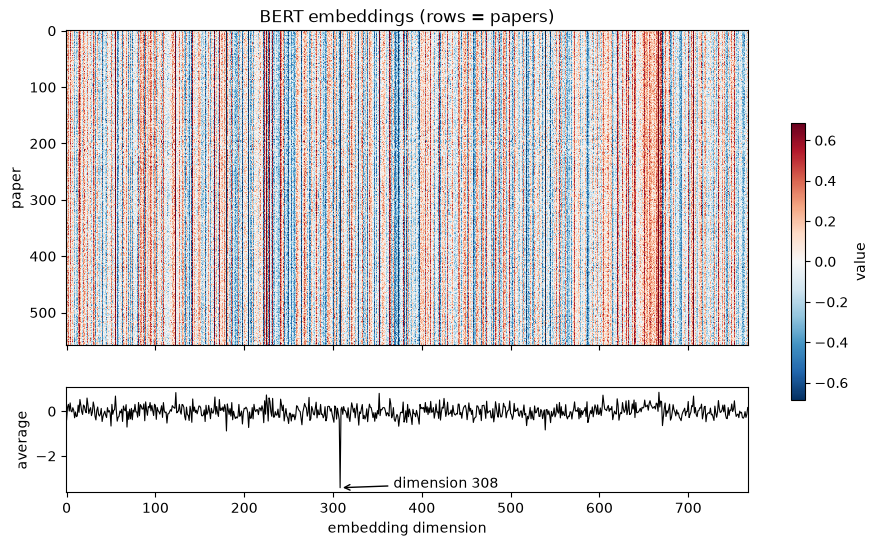

In [8]:
mean_vector = embeddings.mean(axis=0)
share = np.sum(mean_vector ** 2) / np.mean(np.sum(embeddings ** 2, axis=1))
print(f"values range from {embeddings.min():.2f} to {embeddings.max():.2f}; 98% lie in ±{np.percentile(np.abs(embeddings), 98):.2f}")
print(f"the shared average vector makes up {share:.0%} of a typical paper's vector")

limit = np.percentile(np.abs(embeddings), 98)          # robust colour scale
f, axs = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
im = axs[0].imshow(embeddings, cmap='RdBu_r', vmin=-limit, vmax=limit, aspect='auto', interpolation='nearest')
axs[0].set_ylabel('paper'); axs[0].set_title('BERT embeddings (rows = papers)')
plt.colorbar(im, ax=axs, label='value', shrink=0.6)
axs[1].plot(mean_vector, color='black', lw=0.8)
axs[1].set_ylabel('average'); axs[1].set_xlabel('embedding dimension')
top = np.argmax(np.abs(mean_vector))
axs[1].annotate(f"dimension {top}", (top, mean_vector[top]), (top + 60, mean_vector[top]), arrowprops=dict(arrowstyle='->'))
plt.show()

# 3. Cosine Similarity
## 3.1 Comparing two papers
**Cosine similarity** is the cosine of the angle between two vectors: 1 = same direction, 0 = unrelated, −1 = opposite. It ignores the length of the vectors, so a long and a short abstract about the same topic still score high.

```
cos(a, b) = (a · b) / (|a| |b|)
```

We compute it for every pair of papers: a 559 × 559 matrix.

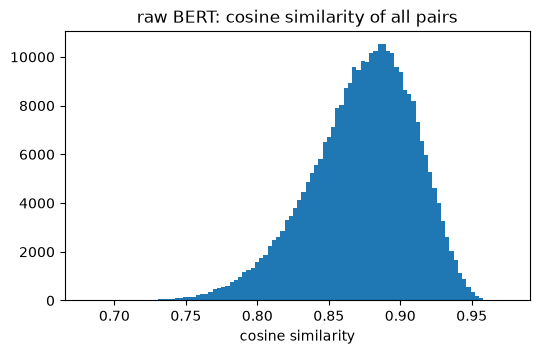

In [9]:
raw_similarity = cosine_similarity(embeddings)
off_diag = ~np.eye(len(embeddings), dtype=bool)      # ignore each paper's similarity with itself

plt.figure(figsize=(6, 3.5))
plt.hist(raw_similarity[off_diag], bins=100)
plt.title('raw BERT: cosine similarity of all pairs'); plt.xlabel('cosine similarity')
plt.show()

## 3.2 Centering: removing what all papers share
Almost every pair has a similarity between 0.75 and 0.95: with raw BERT vectors, *everything* looks similar. All vectors share a large common direction (every text is "academic English"), the bright and dark columns from Section 2.3.

The fix is simple: subtract the **average embedding** from every paper (**centering**), then scale each vector to length 1. What remains is what makes each paper different.

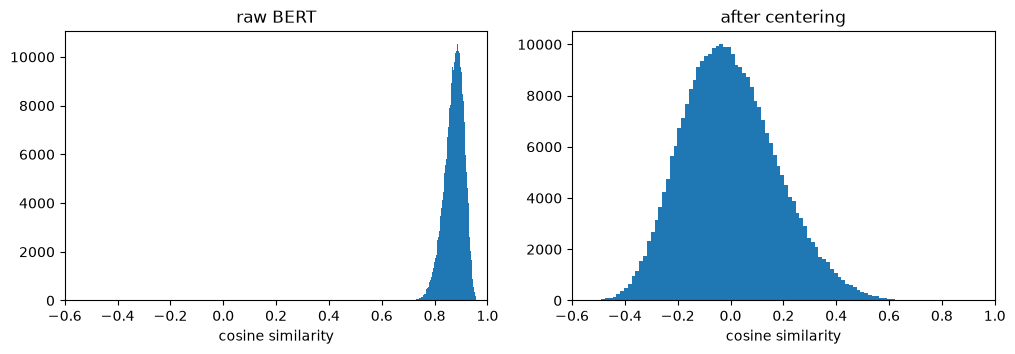

In [10]:
embeddings_centered = embeddings - embeddings.mean(axis=0)
X = embeddings_centered / np.linalg.norm(embeddings_centered, axis=1, keepdims=True)   # length 1

similarity = cosine_similarity(X)

f, axs = plt.subplots(1, 2, figsize=(12, 3.5))
axs[0].hist(raw_similarity[off_diag], bins=100); axs[0].set_title('raw BERT')
axs[1].hist(similarity[off_diag], bins=100);     axs[1].set_title('after centering')
for ax in axs:
    ax.set_xlim(-0.6, 1); ax.set_xlabel('cosine similarity')
plt.show()

The same heatmap after centering: the shared stripes are gone, and what is left is how each paper **differs** from the average paper. These differences are what clustering and similarity work with. In file order the rows look like noise; in Section 4.4 we sort them by cluster and the structure appears.

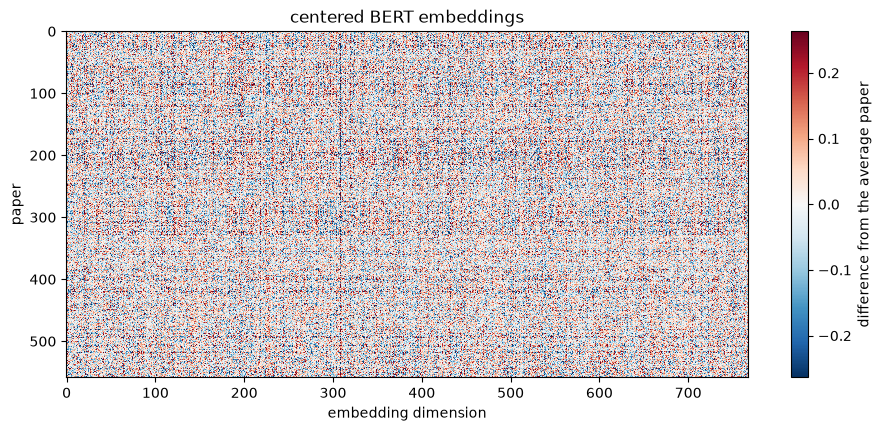

In [11]:
limit_c = np.percentile(np.abs(embeddings_centered), 98)
plt.figure(figsize=(11, 4.5))
plt.imshow(embeddings_centered, cmap='RdBu_r', vmin=-limit_c, vmax=limit_c, aspect='auto', interpolation='nearest')
plt.xlabel('embedding dimension'); plt.ylabel('paper'); plt.title('centered BERT embeddings')
plt.colorbar(label='difference from the average paper')
plt.show()

## 3.3 Does it work? The most similar papers
Pick a paper and list the papers with the highest similarity. If the embeddings capture the topic, the neighbours should be about the same thing.

In [12]:
def most_similar(i, n=5):
    order = np.argsort(-similarity[i])
    order = order[order != i][:n]
    print(f"Paper: {titles[i]}\n")
    for j in order:
        print(f"  {similarity[i, j]:.2f}  {titles[j]}")

most_similar(0)

Paper: Virtual reality applications for the built environment: Research trends and opportunities

  0.75  Building information modelling for off-site construction: Review and future directions
  0.61  Brain computer interfaces for mobile apps: State-of-the-art & future directions
  0.53  Modelling user experience: Integrating user experience research into design education
  0.53  An expandable web-based platform for visually analyzing basin-scale hydro-climate time series data
  0.53  Spatialization methods: A cartographic research agenda for non-geographic information visualization


The neighbours of this review paper are other papers that **review a field or outline future directions**. BERT captures the *kind* of text (review, research agenda) as well as its topic. Keep this in mind when you read the clusters in Section 6.

In [13]:
# try another paper: change the number
most_similar(4)

Paper: DiseaSE: A biomedical text analytics system for disease symptom extraction and characterization

  0.47  P2CS: A two-component system resource for prokaryotic signal transduction research
  0.45  P2TF: A comprehensive resource for analysis of prokaryotic transcription factors
  0.45  Mining and exploring care pathways from electronic medical records with visual analytics
  0.43  Pathways database system: An integrated set of tools for biological pathways
  0.43  An online tool for measuring and visualizing phenotype similarities using HPO


# 4. Cluster the Embeddings
## 4.1 How many clusters? The silhouette score
For each paper, the **silhouette** compares how close it is to its own cluster (*a*) with how close it is to the nearest other cluster (*b*): `s = (b − a) / max(a, b)`.
- close to **1**: clearly in the right cluster
- close to **0**: on the border between clusters
- **negative**: probably in the wrong cluster

We try k = 2 … 14 and compare the average silhouette.

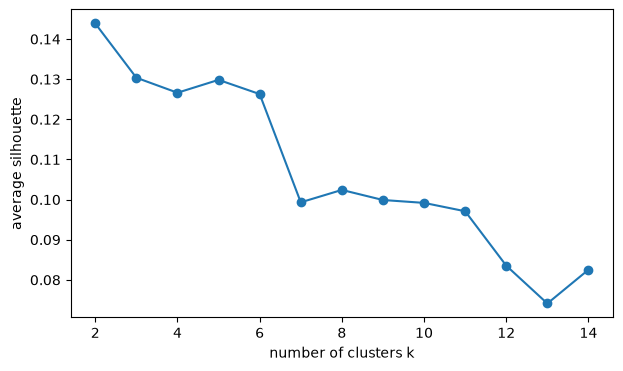

In [14]:
k_values = range(2, 15)
silhouettes = []
for k in k_values:
    labels = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit_predict(X)
    silhouettes.append(silhouette_score(X, labels, metric='cosine'))

plt.figure(figsize=(7, 4))
plt.plot(list(k_values), silhouettes, 'o-')
plt.xlabel('number of clusters k'); plt.ylabel('average silhouette')
plt.show()

## 4.2 Decision
Research topics overlap, so silhouette scores for text stay low (about 0.07–0.15) and there is no sharp peak. Read the plot for a **range**, then choose a k whose clusters you can **name** (Section 6):

- k = 2–6 score highest, but they are broad: at k = 6, image processing and machine learning still fall into one cluster.
- k = 7 separates them; the score drops a little, but every cluster becomes a recognizable topic.
- Section 7 finds the same number of groups with a method that chooses it by itself.

We use **k = 7**. Try k = 5 and k = 10 and compare the results in Section 6.

In [15]:
n_clusters = 7

## 4.3 K-Means
K-Means places *k* centres, assigns each paper to the nearest centre, moves each centre to the mean of its papers, and repeats until nothing changes. `n_init=10` runs it 10 times from different starting centres and keeps the best result. Cluster numbers start at 1.

In [16]:
kmeans = KMeans(n_clusters=n_clusters, random_state=SEED, n_init=10)
df_papers['cluster'] = kmeans.fit_predict(X) + 1
labels = df_papers['cluster'].values

df_papers['cluster'].value_counts().sort_index()

cluster
1     75
2    100
3     88
4     64
5     82
6     67
7     83
Name: count, dtype: int64

## 4.4 The embeddings again, sorted by cluster
Now we sort the papers (rows) by cluster and draw lines between clusters:
- **Left:** the centered embeddings. Columns are grouped by the cluster in which they are highest. Each cluster has its own pattern of high (red) and low (blue) dimensions.
- **Right:** the cosine similarity matrix in the same order. Papers in the same cluster are similar to each other, so bright **blocks along the diagonal** appear. A bright block off the diagonal means two clusters are related.

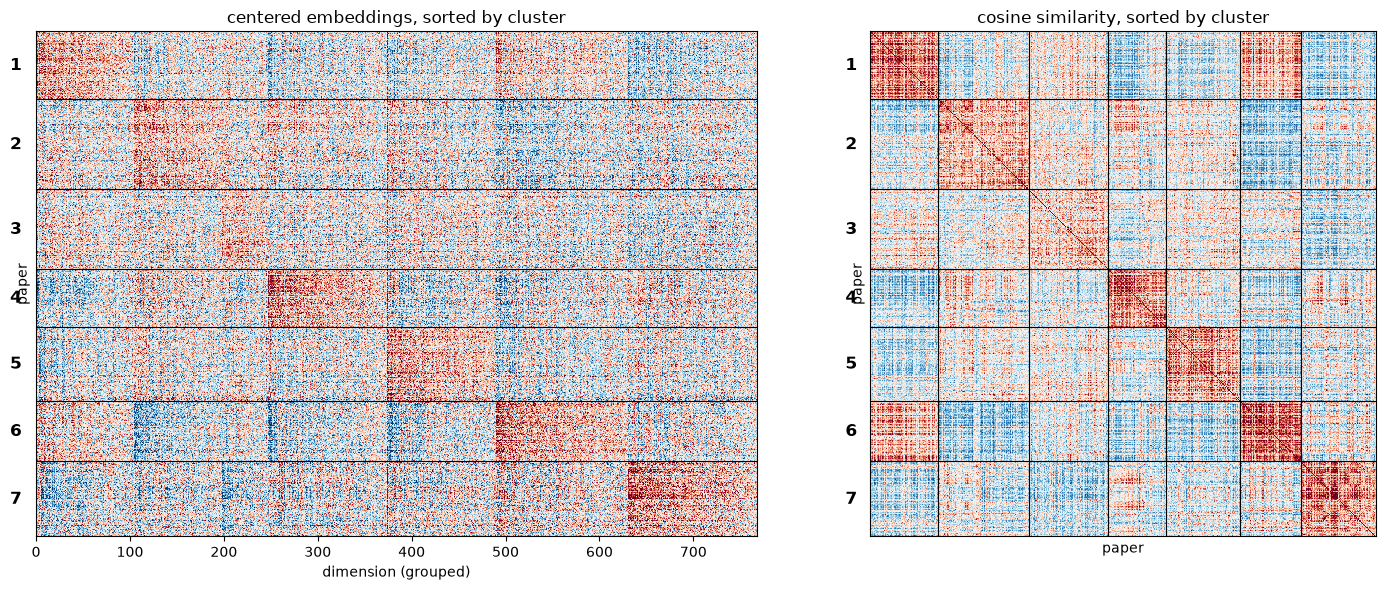

In [17]:
order = np.argsort(labels, kind='stable')                            # papers sorted by cluster
cluster_means = np.array([embeddings_centered[labels == c].mean(axis=0) for c in range(1, n_clusters + 1)])
col_order = np.lexsort((-np.abs(cluster_means).max(axis=0), cluster_means.argmax(axis=0)))
borders = np.cumsum(np.bincount(labels)[1:])[:-1] - 0.5             # where one cluster ends

f, axs = plt.subplots(1, 2, figsize=(15, 6))
axs[0].imshow(embeddings_centered[order][:, col_order], cmap='RdBu_r', vmin=-limit_c, vmax=limit_c,
              aspect='auto', interpolation='nearest')
axs[0].set_title('centered embeddings, sorted by cluster'); axs[0].set_xlabel('dimension (grouped)'); axs[0].set_ylabel('paper')
axs[1].imshow(similarity[np.ix_(order, order)], cmap='RdBu_r', vmin=-0.5, vmax=0.5, interpolation='nearest')
axs[1].set_title('cosine similarity, sorted by cluster'); axs[1].set_xlabel('paper'); axs[1].set_ylabel('paper')
for b in borders:
    axs[0].axhline(b, color='black', lw=0.8)
    axs[1].axhline(b, color='black', lw=0.8); axs[1].axvline(b, color='black', lw=0.8)
centres = np.r_[0, borders + 0.5, len(labels)]
for c in range(n_clusters):
    mid = (centres[c] + centres[c + 1]) / 2
    axs[0].text(-15, mid, str(c + 1), ha='right', va='center', fontsize=12, weight='bold')
    axs[1].text(-15, mid, str(c + 1), ha='right', va='center', fontsize=12, weight='bold')
axs[0].set_yticks([]); axs[1].set_yticks([]); axs[1].set_xticks([])
plt.tight_layout()
plt.show()

# 5. Visualize the Clusters
We project the 768 dimensions to 2D **only to look**. The colours come from the clusters of Section 4.

## 5.1 PCA
PCA finds the two directions with the most variance and projects the papers onto them (a straight-line view).

variance shown by the 2 components: 19%


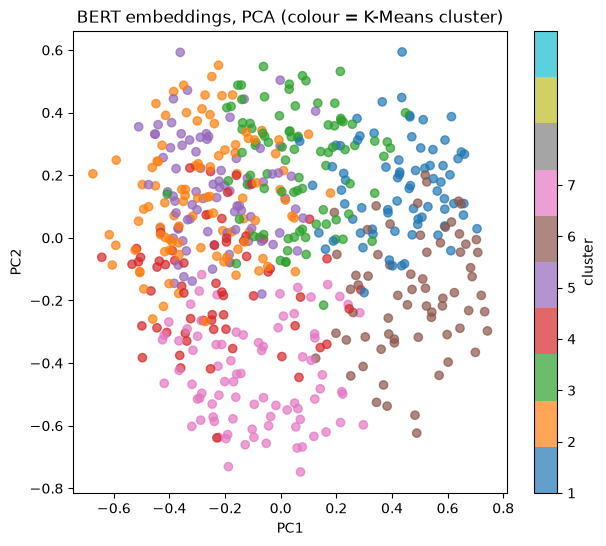

In [18]:
pca = PCA(n_components=2, random_state=SEED)
xy_pca = pca.fit_transform(X)
print("variance shown by the 2 components:", f"{pca.explained_variance_ratio_.sum():.0%}")

f, ax = plt.subplots(1, 1, figsize=(7, 6))
sc = ax.scatter(xy_pca[:, 0], xy_pca[:, 1], c=labels, cmap='tab10', vmin=1, vmax=10, alpha=0.7)
ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
ax.set_title('BERT embeddings, PCA (colour = K-Means cluster)')
plt.colorbar(sc, ticks=range(1, n_clusters + 1), label='cluster')
plt.show()

## 5.2 t-SNE
t-SNE is non-linear: it keeps each paper's nearest neighbours close in 2D, so groups separate better than in PCA. Distances **between** groups and group **sizes** are not meaningful on a t-SNE map.

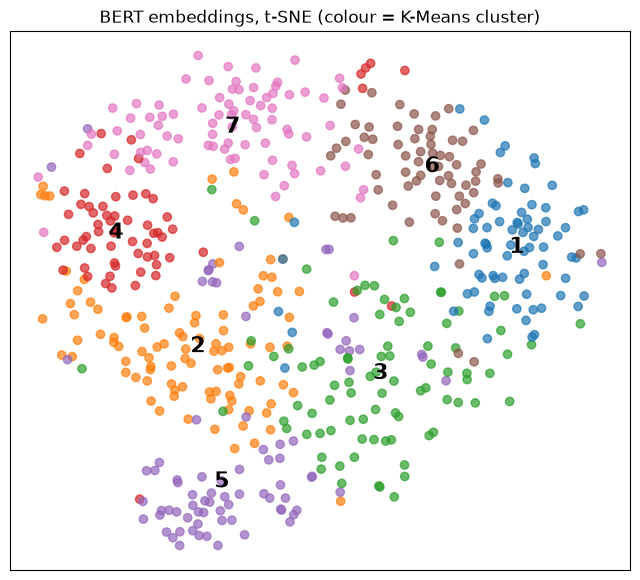

In [19]:
xy_tsne = TSNE(n_components=2, perplexity=30, metric='cosine', init='pca', random_state=SEED).fit_transform(X)

f, ax = plt.subplots(1, 1, figsize=(8, 7))
ax.scatter(xy_tsne[:, 0], xy_tsne[:, 1], c=labels, cmap='tab10', vmin=1, vmax=10, alpha=0.7)
for c in range(1, n_clusters + 1):                 # cluster number at the cluster centre
    cx, cy = np.median(xy_tsne[labels == c], axis=0)
    ax.text(cx, cy, str(c), fontsize=16, weight='bold', ha='center', va='center')
ax.set_title('BERT embeddings, t-SNE (colour = K-Means cluster)')
ax.set_xticks([]); ax.set_yticks([])
plt.show()

# 6. Interpret the Clusters
The 768 numbers have no names, so we describe each cluster with the papers themselves:
- **Representative titles:** the papers closest to the cluster centre (highest cosine similarity with the centre).
- **Typical title words:** words that are frequent in this cluster's titles **and** more frequent there than in all titles. Score = count × log(share in cluster / share overall).

In [20]:
stop_words = ENGLISH_STOP_WORDS | {'using', 'based', 'case', 'study', 'approach', 'new', 'towards'}

def title_words(title_list):
    words = re.findall(r'[a-z]+', ' '.join(title_list).lower())
    return Counter(w for w in words if w not in stop_words and len(w) > 2)

all_words = title_words(titles)

def describe_clusters(n_titles=4, n_words=6):
    names = {}
    for c in range(1, n_clusters + 1):
        idx = np.where(labels == c)[0]
        centre = X[idx].mean(axis=0)
        closest = idx[np.argsort(-(X[idx] @ centre))[:n_titles]]

        counts = title_words(titles[idx])
        score = {w: n * np.log((n / len(idx)) / (all_words[w] / len(titles)))
                 for w, n in counts.items() if n >= 3}
        top = sorted(score, key=score.get, reverse=True)[:n_words]
        names[c] = ", ".join(top[:3])

        print(f"=== Cluster {c}  ({len(idx)} papers)   typical words: {', '.join(top)}")
        for j in closest:
            print("   -", titles[j])
    return names

cluster_names = describe_clusters()
df_papers['cluster_name'] = df_papers['cluster'].map(cluster_names)

=== Cluster 1  (75 papers)   typical words: dimensional, high, classification, sets, self, reduction
   - Self-organizing maps with information theoretic learning
   - Adaptive local dissimilarity measures for discriminative dimension reduction of labeled data
   - Parametric nonlinear dimensionality reduction using kernel t-SNE
   - Multi-layered perceptron based dimensionality reduction
=== Cluster 2  (100 papers)   typical words: visual, analysis, information, process, design, analytics
   - Multi-faceted insight through interoperable visual information analysis paradigms
   - The notion of overview in information visualization
   - Spatialization methods: A cartographic research agenda for non-geographic information visualization
   - Operator interaction framework for visualization systems
=== Cluster 3  (88 papers)   typical words: large, text, visualization, visualizing, technique, information
   - Navigating hierarchies with structure-based brushes
   - 3D space framework for t

# 7. Similarity Network and Communities
Clusters put every paper in one box. A network shows **which papers are closest**, which papers **bridge** two topics, and gives a second way to find groups.

## 7.1 Nearest-neighbour graph
Every paper is linked to its **10 most similar papers**. Unlike one global threshold, this keeps every paper connected, also papers in small topics.

In [21]:
n_neighbors = 10
sim = similarity.copy()
np.fill_diagonal(sim, -1)                                  # a paper is not its own neighbour
neighbors = np.argsort(-sim, axis=1)[:, :n_neighbors]

G = nx.Graph()
for i, row in df_papers.iterrows():
    G.add_node(i, title=row['Title'], year=int(row['Year']),
               cluster=int(row['cluster']), cluster_name=row['cluster_name'])
for i in range(len(df_papers)):
    for j in neighbors[i]:
        G.add_edge(i, int(j), weight=float(sim[i, j]))

print(G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges,",
      nx.number_connected_components(G), "connected component(s)")

559 nodes, 4093 edges, 1 connected component(s)


## 7.2 Community detection (Louvain)
**Louvain** finds groups of papers with many links inside and few links between them. It chooses the number of groups by itself, so it is an independent check of our k.

**Modularity** measures how well the communities separate (above ~0.3 means a clear structure). The **adjusted Rand index (ARI)** compares communities with clusters: 1 = identical, 0 = no better than random.

In [22]:
communities = sorted(nx.community.louvain_communities(G, weight='weight', seed=SEED), key=len, reverse=True)

community = np.zeros(len(df_papers), dtype=int)
for c, members in enumerate(communities, start=1):
    community[list(members)] = c
df_papers['community'] = community
nx.set_node_attributes(G, {i: int(c) for i, c in enumerate(community)}, 'community')

print("communities:", len(communities), " sizes:", [len(c) for c in communities])
print("modularity:", round(nx.community.modularity(G, communities, weight='weight'), 2))
print("ARI communities vs clusters:", round(adjusted_rand_score(community, labels), 2))

communities: 7  sizes: [111, 110, 87, 73, 70, 68, 40]
modularity: 0.6
ARI communities vs clusters: 0.51


Which clusters end up in which community? Each row is a K-Means cluster; each column a community.

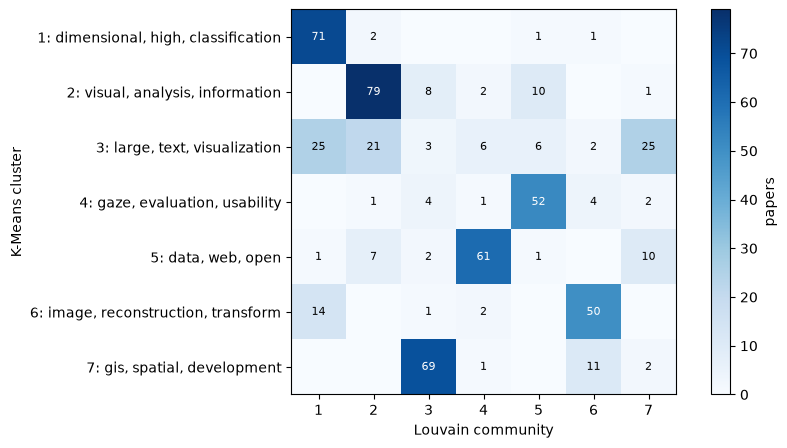

In [23]:
crosstab = pd.crosstab(df_papers['cluster'].astype(str) + ': ' + df_papers['cluster_name'],
                       df_papers['community'])

f, ax = plt.subplots(1, 1, figsize=(9, 5))
im = ax.imshow(crosstab.values, cmap='Blues')
ax.set_xticks(range(crosstab.shape[1]), crosstab.columns)
ax.set_yticks(range(crosstab.shape[0]), crosstab.index)
ax.set_xlabel('Louvain community'); ax.set_ylabel('K-Means cluster')
for (r, c), v in np.ndenumerate(crosstab.values):
    if v: ax.text(c, r, v, ha='center', va='center', fontsize=8,
                  color='white' if v > crosstab.values.max() / 2 else 'black')
plt.colorbar(im, label='papers')
plt.show()

## 7.3 Draw the network

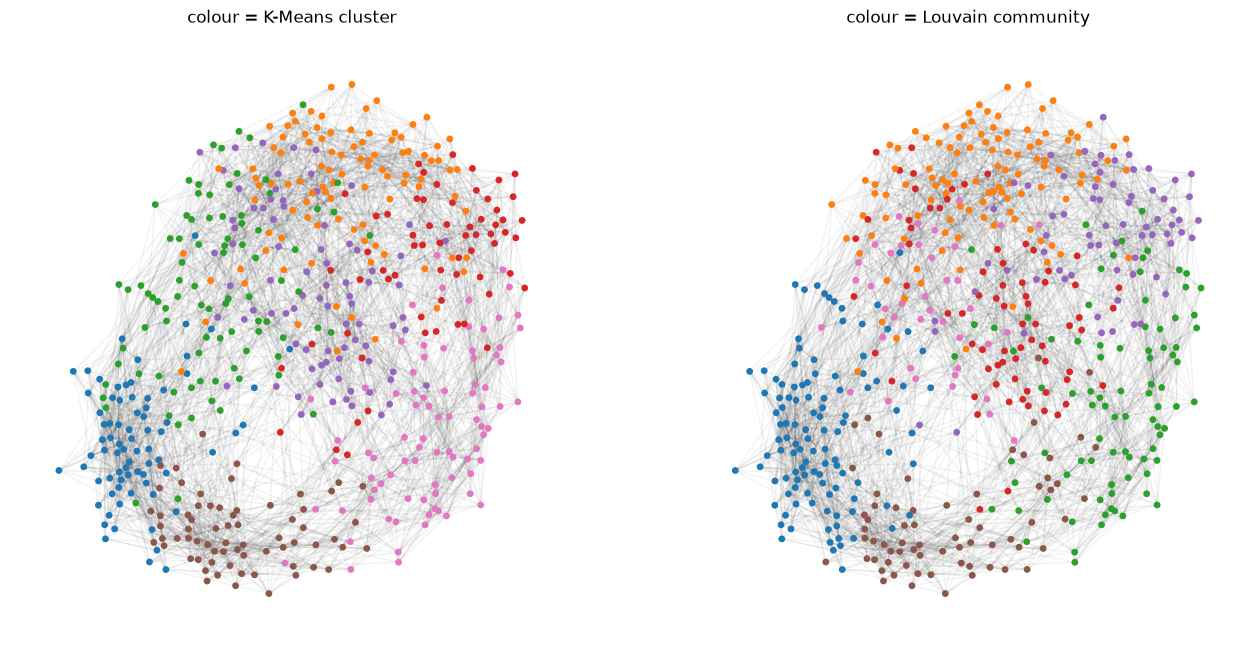

In [24]:
pos = nx.spring_layout(G, seed=SEED, weight='weight')

f, axs = plt.subplots(1, 2, figsize=(16, 8))
for ax, attr, title in [(axs[0], 'cluster', 'colour = K-Means cluster'),
                        (axs[1], 'community', 'colour = Louvain community')]:
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.05)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=15, cmap='tab10', vmin=1, vmax=10,
                           node_color=[G.nodes[n][attr] for n in G.nodes])
    ax.set_title(title); ax.axis('off')
plt.show()

## 7.4 Export for Gephi
Open `Documents_bert.gexf` in Gephi. Each node has `title`, `year`, `cluster`, `cluster_name` and `community`, so you can colour, size and label the papers by any of them.

In [25]:
nx.write_gexf(G, "Documents_bert.gexf")
df_papers[['EID', 'Title', 'Year', 'cluster', 'cluster_name', 'community']].head()

,EID,Title,Year,cluster,cluster_name,community
0,2-s2.0-85086464158,Virtual reality applications for the built env...,2020,2,"visual, analysis, information",2
1,2-s2.0-85082875828,"Self-tracking while doing sport: Comfort, moti...",2020,2,"visual, analysis, information",5
2,2-s2.0-85078194587,"Bridge damage: Detection, IFC-based semantic e...",2020,5,"data, web, open",4
3,2-s2.0-85075706132,VR system for spatio-temporal visualization of...,2019,3,"large, text, visualization",7
4,2-s2.0-85074886243,DiseaSE: A biomedical text analytics system fo...,2019,5,"data, web, open",4
